In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")

In [2]:
wine = pd.read_csv("data/winequality-red.csv", sep=";")
print(wine.shape)
wine.head()

(1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
wine.info()
print(wine.isna().sum())
print("Duplicate rows:", wine.duplicated().sum())
wine.describe().round(2)

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free su

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00
mean,8.32,0.53,0.27,2.54,0.09,15.87,46.47,1.00,3.31,0.66,10.42,5.64
std,1.74,0.18,0.19,1.41,0.05,10.46,32.90,0.00,0.15,0.17,1.07,0.81
min,4.60,0.12,0.00,0.90,0.01,1.00,6.00,0.99,2.74,0.33,8.40,3.00
25%,7.10,0.39,0.09,1.90,0.07,7.00,22.00,1.00,3.21,0.55,9.50,5.00
50%,7.90,0.52,0.26,2.20,0.08,14.00,38.00,1.00,3.31,0.62,10.20,6.00
75%,9.20,0.64,0.42,2.60,0.09,21.00,62.00,1.00,3.40,0.73,11.10,6.00
max,15.90,1.58,1.00,15.50,0.61,72.00,289.00,1.00,4.01,2.00,14.90,8.00


quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

quality
3     0.6
4     3.3
5    42.6
6    39.9
7    12.4
8     1.1
Name: proportion, dtype: float64


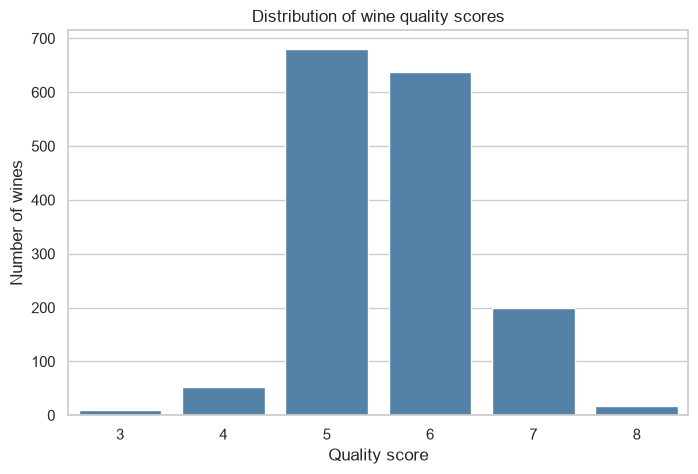

In [4]:
print(wine["quality"].value_counts().sort_index())
print()
print((wine["quality"].value_counts(normalize=True).sort_index() * 100).round(1))

plt.figure(figsize=(8, 5))
sns.countplot(data=wine, x="quality", color="steelblue")
plt.title("Distribution of wine quality scores")
plt.xlabel("Quality score")
plt.ylabel("Number of wines")
plt.show()

In [5]:
wine_clean = wine.drop_duplicates().reset_index(drop=True)
print("Before:", wine.shape, "| After:", wine_clean.shape)
print(wine_clean["quality"].value_counts().sort_index())

Before: (1599, 12) | After: (1359, 12)
quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64


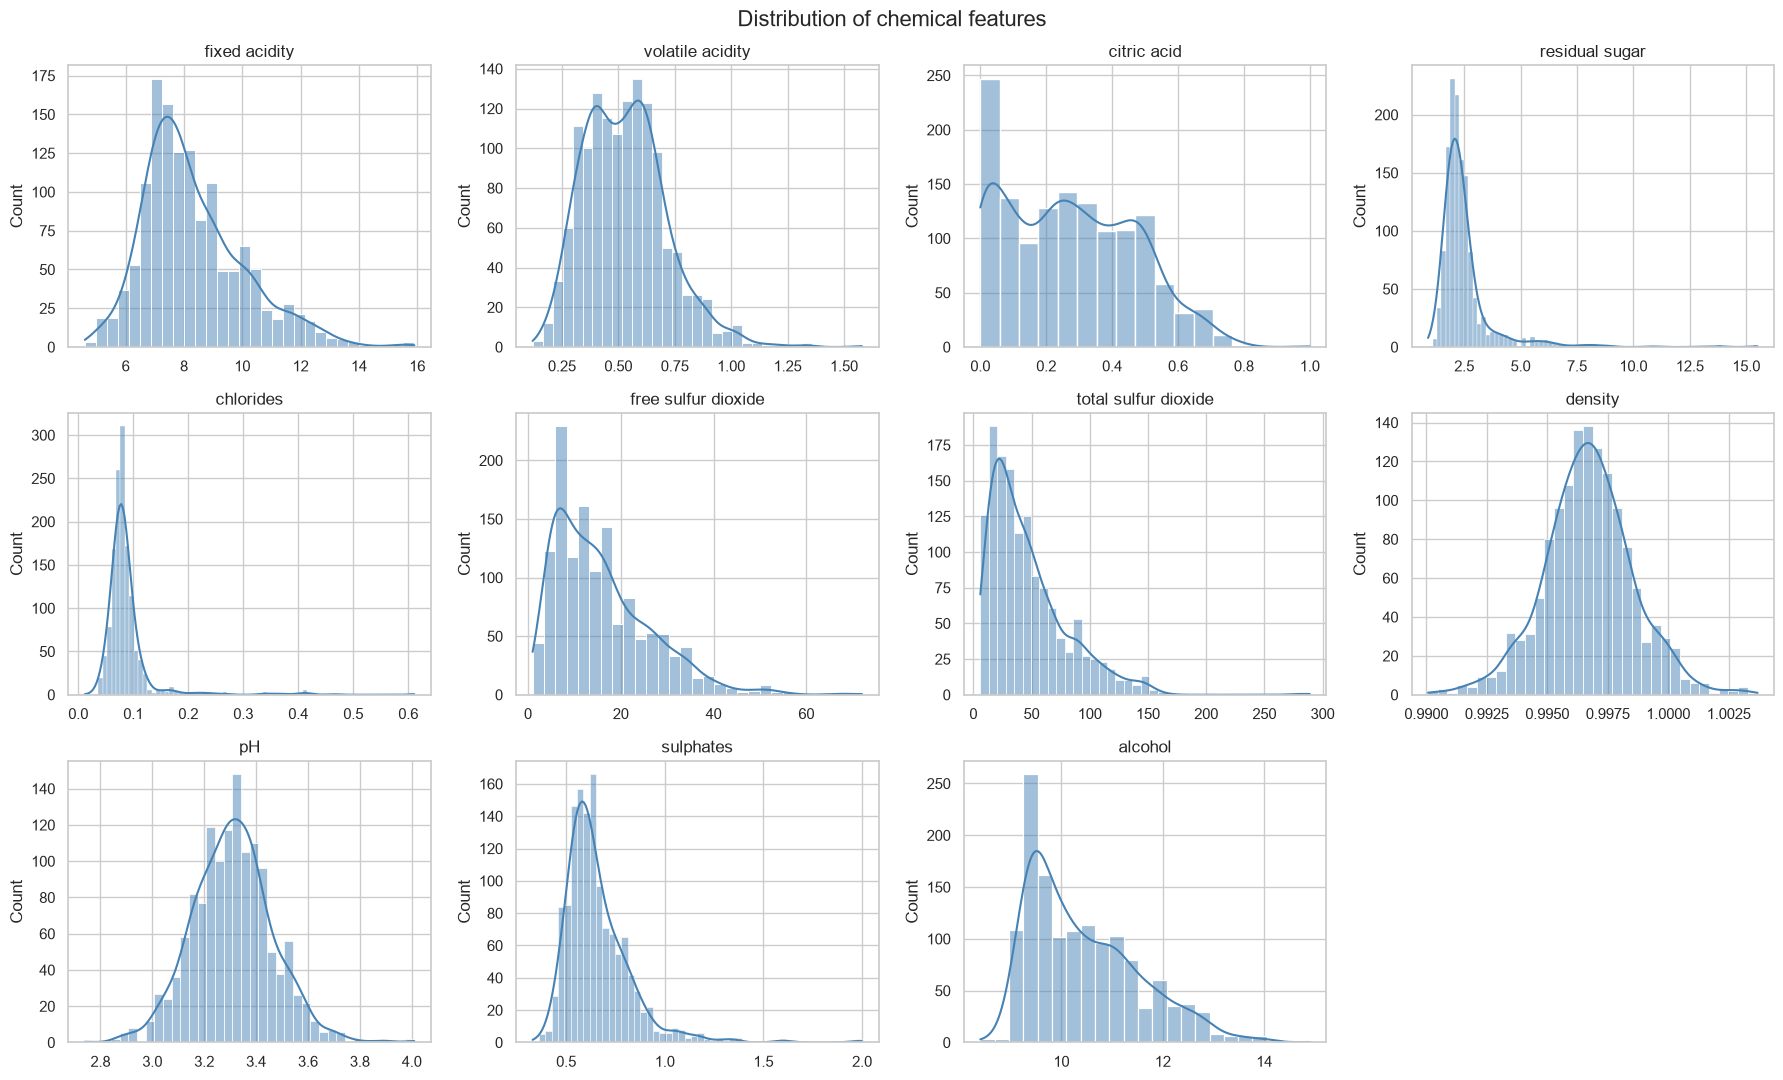

In [6]:
features = [c for c in wine_clean.columns if c != "quality"]

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(wine_clean[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(col)
    ax.set_xlabel("")
axes.ravel()[-1].axis("off")
plt.suptitle("Distribution of chemical features", fontsize=16)
plt.tight_layout()
plt.show()

In [7]:
print(wine_clean[features].skew().sort_values(ascending=False).round(2))

chlorides               5.50
residual sugar          4.55
sulphates               2.41
total sulfur dioxide    1.54
free sulfur dioxide     1.23
fixed acidity           0.94
alcohol                 0.86
volatile acidity        0.73
citric acid             0.31
pH                      0.23
density                 0.04
dtype: float64


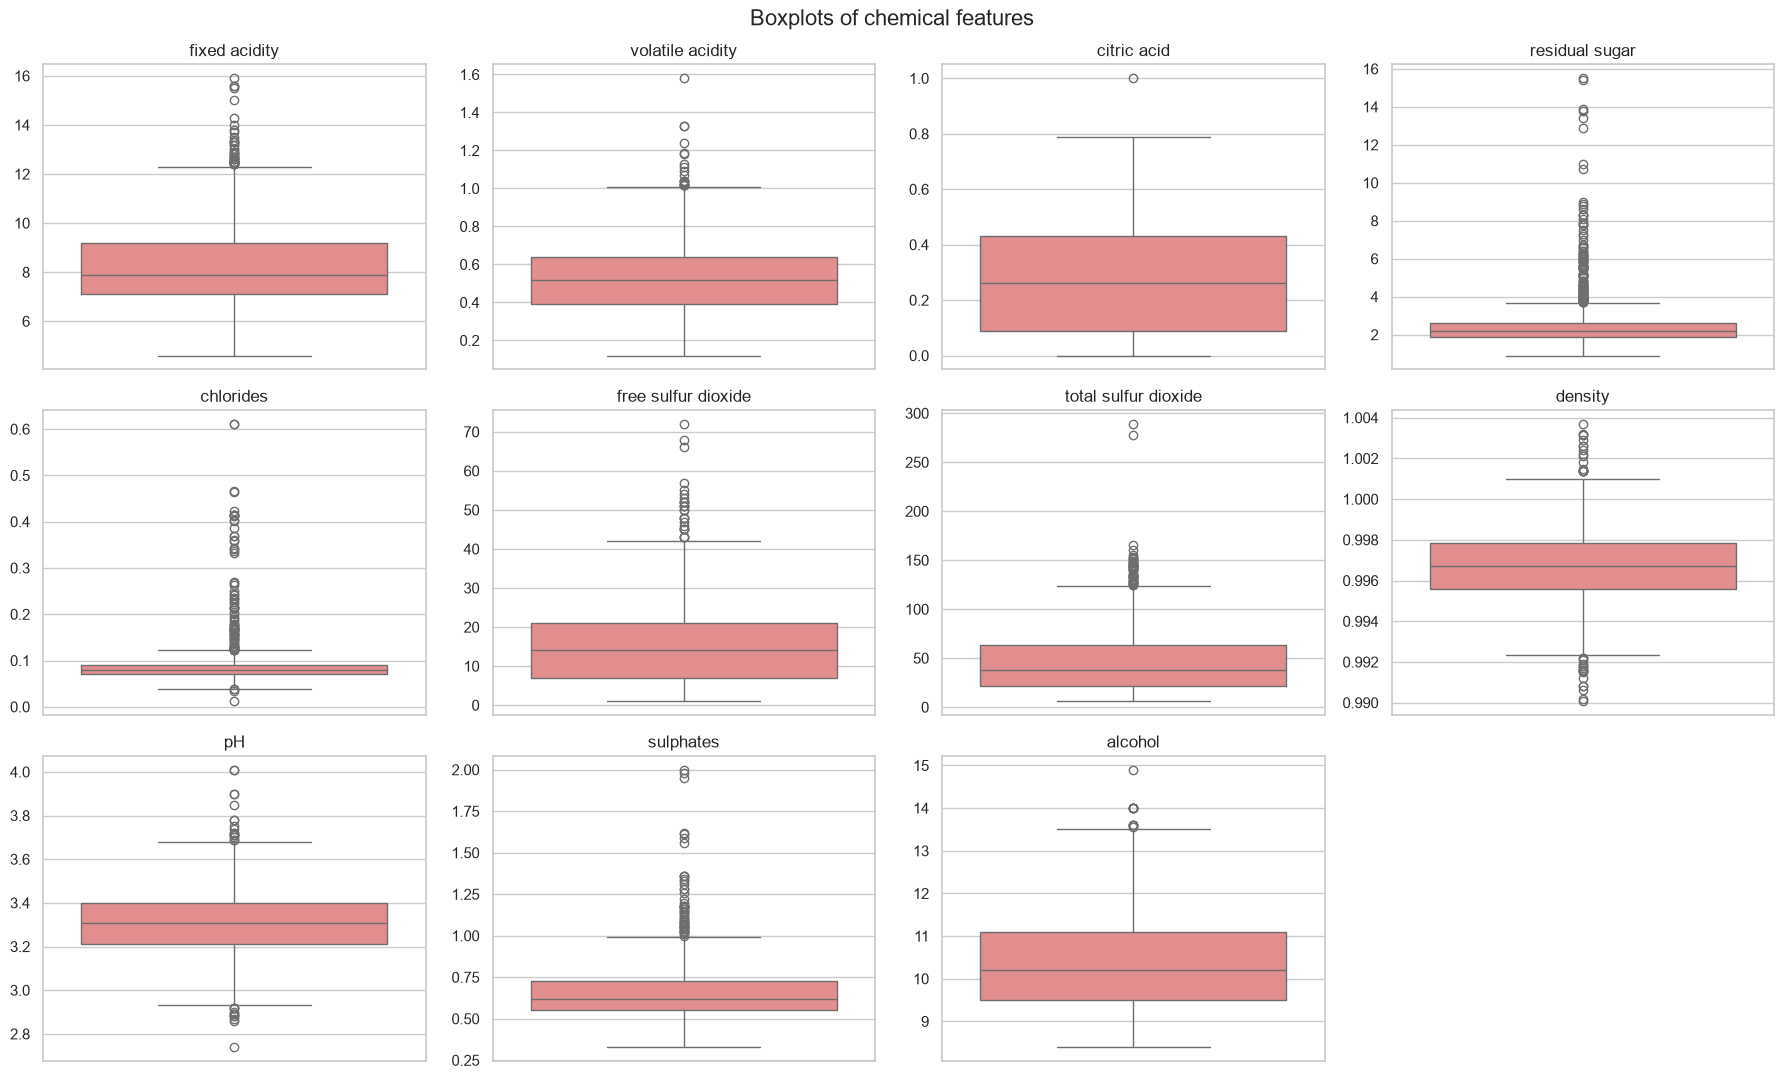

In [8]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(y=wine_clean[col], ax=ax, color="lightcoral")
    ax.set_title(col)
    ax.set_ylabel("")
axes.ravel()[-1].axis("off")
plt.suptitle("Boxplots of chemical features", fontsize=16)
plt.tight_layout()
plt.show()

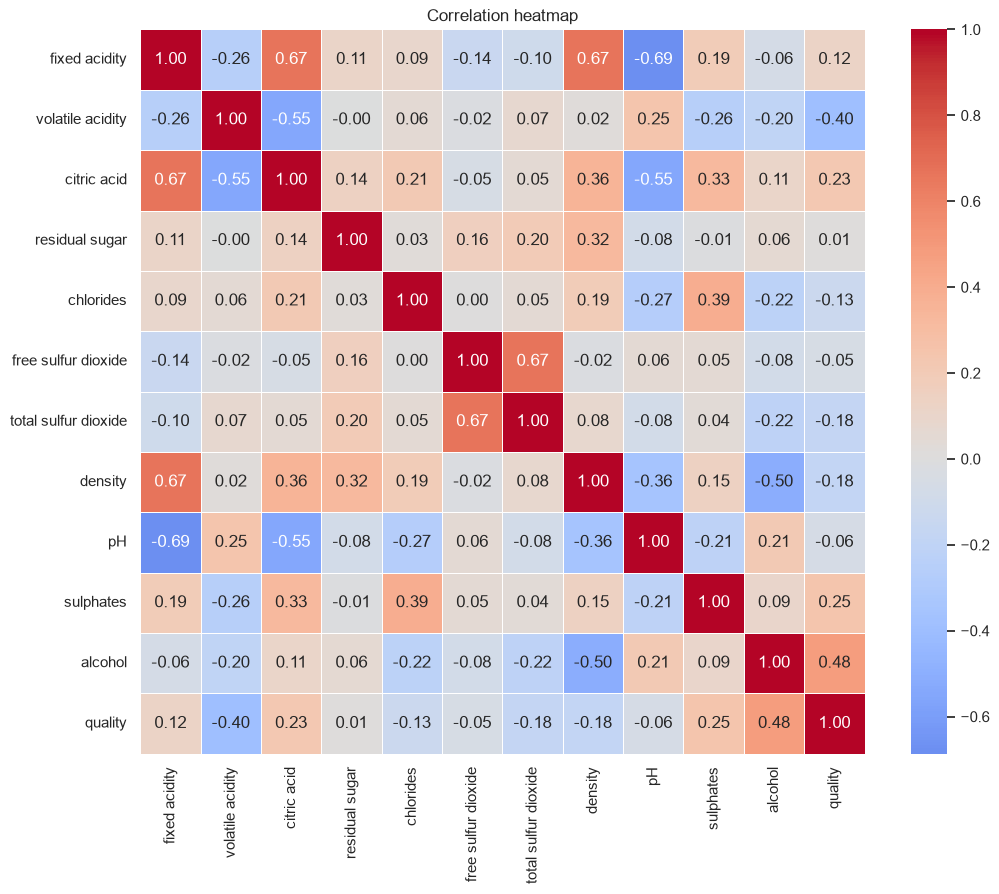

In [9]:
plt.figure(figsize=(11, 9))
corr = wine_clean.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=0.5)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

In [10]:
print(corr["quality"].drop("quality").sort_values(ascending=False).round(3))

alcohol                 0.480
sulphates               0.249
citric acid             0.228
fixed acidity           0.119
residual sugar          0.014
free sulfur dioxide    -0.050
pH                     -0.055
chlorides              -0.131
total sulfur dioxide   -0.178
density                -0.184
volatile acidity       -0.395
Name: quality, dtype: float64


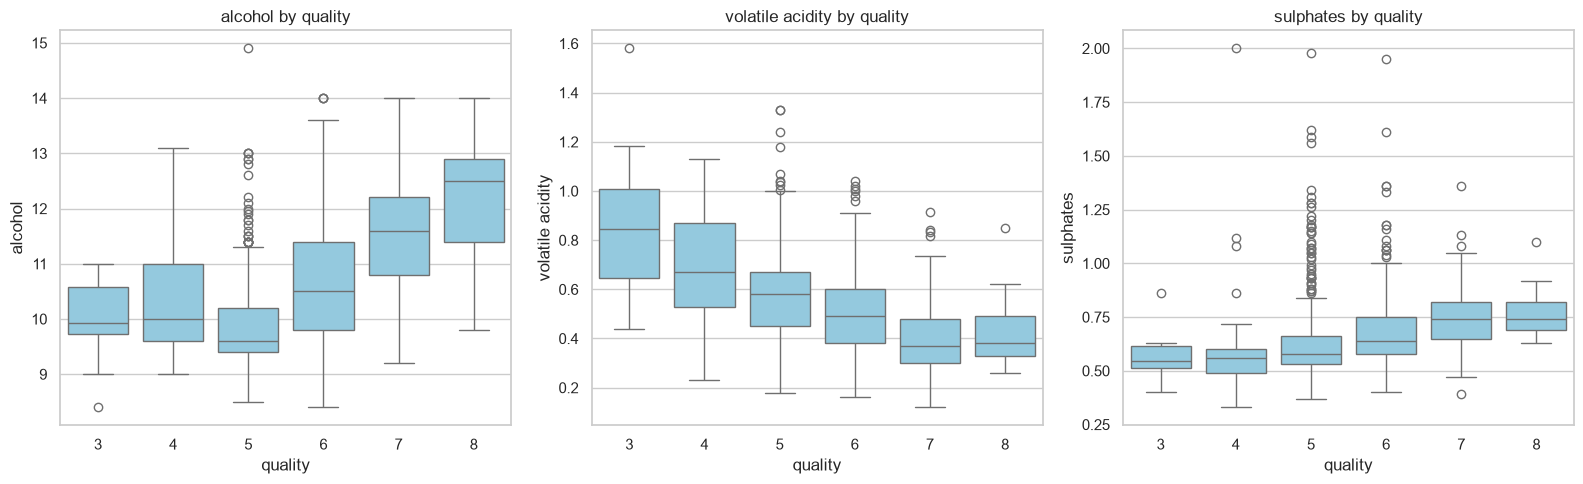

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, ["alcohol", "volatile acidity", "sulphates"]):
    sns.boxplot(data=wine_clean, x="quality", y=col, ax=ax, color="skyblue")
    ax.set_title(f"{col} by quality")
plt.tight_layout()
plt.show()

In [12]:
qc = wine_clean["quality"].value_counts().sort_index()
qp = (qc / qc.sum() * 100).round(1)
print(pd.DataFrame({"count": qc, "percent": qp}))

         count  percent
quality                
3           10      0.7
4           53      3.9
5          577     42.5
6          535     39.4
7          167     12.3
8           17      1.3


In [13]:
print("Share of quality 5 and 6:", round(qp[[5, 6]].sum(), 1), "%")
print("Share of quality 3, 4 and 8:", round(qp[[3, 4, 8]].sum(), 1), "%")
print("Accuracy of always predicting 5:", round(qc[5] / qc.sum() * 100, 1), "%")
print("Expected test wines at 20% split:")
print((qc * 0.2).round(1))

Share of quality 5 and 6: 81.9 %
Share of quality 3, 4 and 8: 5.9 %
Accuracy of always predicting 5: 42.5 %
Expected test wines at 20% split:
quality
3      2.0
4     10.6
5    115.4
6    107.0
7     33.4
8      3.4
Name: count, dtype: float64


In [14]:
opt_a = (wine_clean["quality"] >= 6).map({True: "good", False: "bad"})
opt_b = (wine_clean["quality"] >= 7).map({True: "good", False: "bad"})
opt_c = pd.cut(wine_clean["quality"], bins=[0, 4, 6, 10], labels=["low", "medium", "high"])

print("Option A: good if quality >= 6")
print(opt_a.value_counts(normalize=True).mul(100).round(1))
print()
print("Option B: good if quality >= 7")
print(opt_b.value_counts(normalize=True).mul(100).round(1))
print()
print("Option C: low (3-4) / medium (5-6) / high (7-8)")
print(opt_c.value_counts(normalize=True).mul(100).round(1))

Option A: good if quality >= 6
quality
good    52.9
bad     47.1
Name: proportion, dtype: float64

Option B: good if quality >= 7
quality
bad     86.5
good    13.5
Name: proportion, dtype: float64

Option C: low (3-4) / medium (5-6) / high (7-8)
quality
medium    81.8
high      13.5
low        4.6
Name: proportion, dtype: float64


In [15]:
wine_clean["quality_label"] = (wine_clean["quality"] >= 6).astype(int)
print(wine_clean["quality_label"].value_counts())

quality_label
1    719
0    640
Name: count, dtype: int64


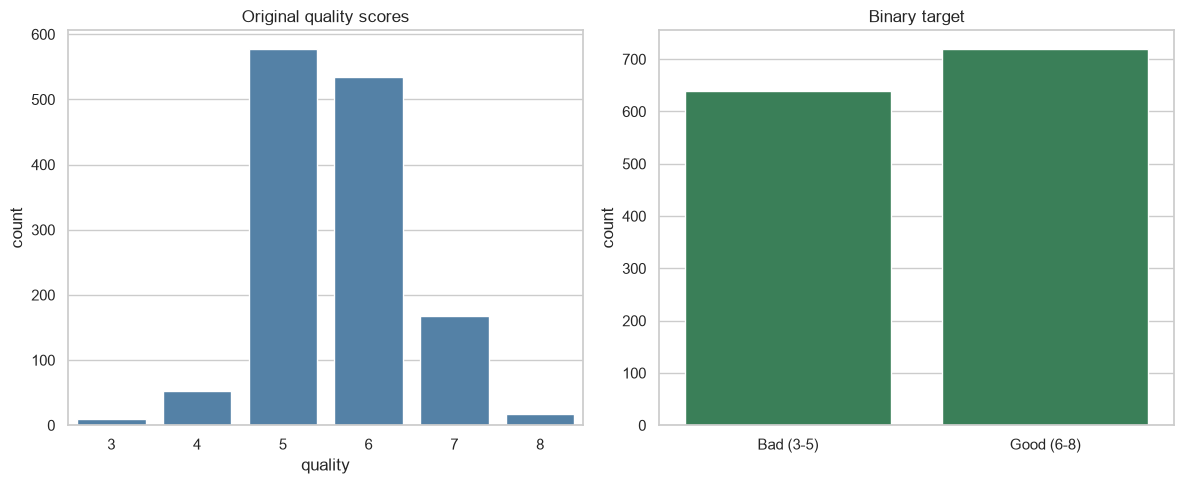

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sns.countplot(data=wine_clean, x="quality", color="steelblue", ax=ax[0])
ax[0].set_title("Original quality scores")
sns.countplot(data=wine_clean, x="quality_label", color="seagreen", ax=ax[1])
ax[1].set_xticks([0, 1])
ax[1].set_xticklabels(["Bad (3-5)", "Good (6-8)"])
ax[1].set_title("Binary target")
ax[1].set_xlabel("")
plt.tight_layout()
plt.show()

## Class Imbalance and Feature Engineering

### Is there class imbalance?
Yes. After removing 240 duplicate rows, the dataset has 1,359 wines, and the quality scores are strongly concentrated in the middle:

| Quality | Wines | Share |
|---|---|---|
| 3 | 10 | 0.7% |
| 4 | 53 | 3.9% |
| 5 | 577 | 42.5% |
| 6 | 535 | 39.4% |
| 7 | 167 | 12.3% |
| 8 | 17 | 1.3% |

Quality 5 and 6 together make up 81.9% of the data, while quality 3, 4 and 8 together make up only 5.9%.

### How does this affect modelling?
- **Accuracy is misleading.** A model that always predicts quality 5 would already score 42.5% accuracy without learning anything.
- **Rare classes get ignored.** Classifiers optimise overall performance, so they tend to favour the majority classes (5 and 6) and rarely predict 3, 4 or 8.
- **Evaluation is unreliable for rare classes.** With a 20% test split, the test set would contain only about 2 wines of quality 3 and 3 wines of quality 8, so per-class precision and recall for these scores would be meaningless.
- **Learning is hard.** With only 10 and 17 examples, no model can learn what a quality 3 or quality 8 wine looks like.

### Binning options compared
| Option | Grouping | Resulting class split |
|---|---|---|
| A | Bad (3-5) vs Good (6-8) | 47.1% bad / 52.9% good |
| B | Bad (3-6) vs Good (7-8) | 86.5% bad / 13.5% good |
| C | Low (3-4) / Medium (5-6) / High (7-8) | 4.6% / 81.8% / 13.5% |

### Decision: binary target (Option A)
Quality is converted into a binary label: **good (quality >= 6)** and **bad (quality <= 5)**, giving 719 good wines and 640 bad wines.

**Justification:**
1. It produces nearly balanced classes (52.9% / 47.1%), so accuracy becomes a meaningful metric and models are not biased toward one class.
2. It removes the near-empty classes (3, 4 and 8), which have too few samples to learn from or to evaluate.
3. It matches a practical question for a winery: will this wine be rated good or not?
4. Options B and C stay heavily imbalanced (13.5% good, and 81.8% medium), which would bring back the problem we are trying to avoid.

**Trade-off:** information is lost, since a quality 6 and a quality 8 wine are both labelled good. The model can no longer predict the exact score.

In [17]:
X = wine_clean.drop(columns=["quality", "quality_label"])
y = wine_clean["quality_label"]
print(X.shape, y.shape)
print(list(X.columns))

(1359, 11) (1359,)
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (1087, 11) | Test: (272, 11)


In [19]:
print("Full data:\n", y.value_counts(normalize=True).mul(100).round(1))
print("Train:\n", y_train.value_counts(normalize=True).mul(100).round(1))
print("Test:\n", y_test.value_counts(normalize=True).mul(100).round(1))

Full data:
 quality_label
1    52.9
0    47.1
Name: proportion, dtype: float64
Train:
 quality_label
1    52.9
0    47.1
Name: proportion, dtype: float64
Test:
 quality_label
1    52.9
0    47.1
Name: proportion, dtype: float64


In [20]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [21]:
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
print("Random Forest accuracy:", round(accuracy_score(y_test, rf_pred), 4))

Random Forest accuracy: 0.7574


In [22]:
sgd = SGDClassifier(max_iter=1000, random_state=42)
sgd.fit(X_train_scaled, y_train)
sgd_pred = sgd.predict(X_test_scaled)
print("SGD accuracy:", round(accuracy_score(y_test, sgd_pred), 4))

SGD accuracy: 0.7243


In [23]:
svc = SVC(kernel="rbf", random_state=42)
svc.fit(X_train_scaled, y_train)
svc_pred = svc.predict(X_test_scaled)
print("SVC accuracy:", round(accuracy_score(y_test, svc_pred), 4))

SVC accuracy: 0.7537


In [24]:
train_scores = {
    "Random Forest": accuracy_score(y_train, rf.predict(X_train)),
    "SGD": accuracy_score(y_train, sgd.predict(X_train_scaled)),
    "SVC": accuracy_score(y_train, svc.predict(X_train_scaled))
}
test_scores = {
    "Random Forest": accuracy_score(y_test, rf_pred),
    "SGD": accuracy_score(y_test, sgd_pred),
    "SVC": accuracy_score(y_test, svc_pred)
}
print(pd.DataFrame({"Train": train_scores, "Test": test_scores}).round(3))

               Train   Test
Random Forest  1.000  0.757
SGD            0.740  0.724
SVC            0.791  0.754


In [25]:
print("RANDOM FOREST")
print("Accuracy:", round(accuracy_score(y_test, rf_pred), 4))
print(classification_report(y_test, rf_pred, target_names=["Bad", "Good"]))

RANDOM FOREST
Accuracy: 0.7574
              precision    recall  f1-score   support

         Bad       0.73      0.77      0.75       128
        Good       0.79      0.74      0.76       144

    accuracy                           0.76       272
   macro avg       0.76      0.76      0.76       272
weighted avg       0.76      0.76      0.76       272



In [26]:
print("SGD")
print("Accuracy:", round(accuracy_score(y_test, sgd_pred), 4))
print(classification_report(y_test, sgd_pred, target_names=["Bad", "Good"]))

SGD
Accuracy: 0.7243
              precision    recall  f1-score   support

         Bad       0.70      0.73      0.71       128
        Good       0.75      0.72      0.73       144

    accuracy                           0.72       272
   macro avg       0.72      0.72      0.72       272
weighted avg       0.73      0.72      0.72       272



In [27]:
print("SVC")
print("Accuracy:", round(accuracy_score(y_test, svc_pred), 4))
print(classification_report(y_test, svc_pred, target_names=["Bad", "Good"]))

SVC
Accuracy: 0.7537
              precision    recall  f1-score   support

         Bad       0.73      0.77      0.75       128
        Good       0.78      0.74      0.76       144

    accuracy                           0.75       272
   macro avg       0.75      0.75      0.75       272
weighted avg       0.76      0.75      0.75       272



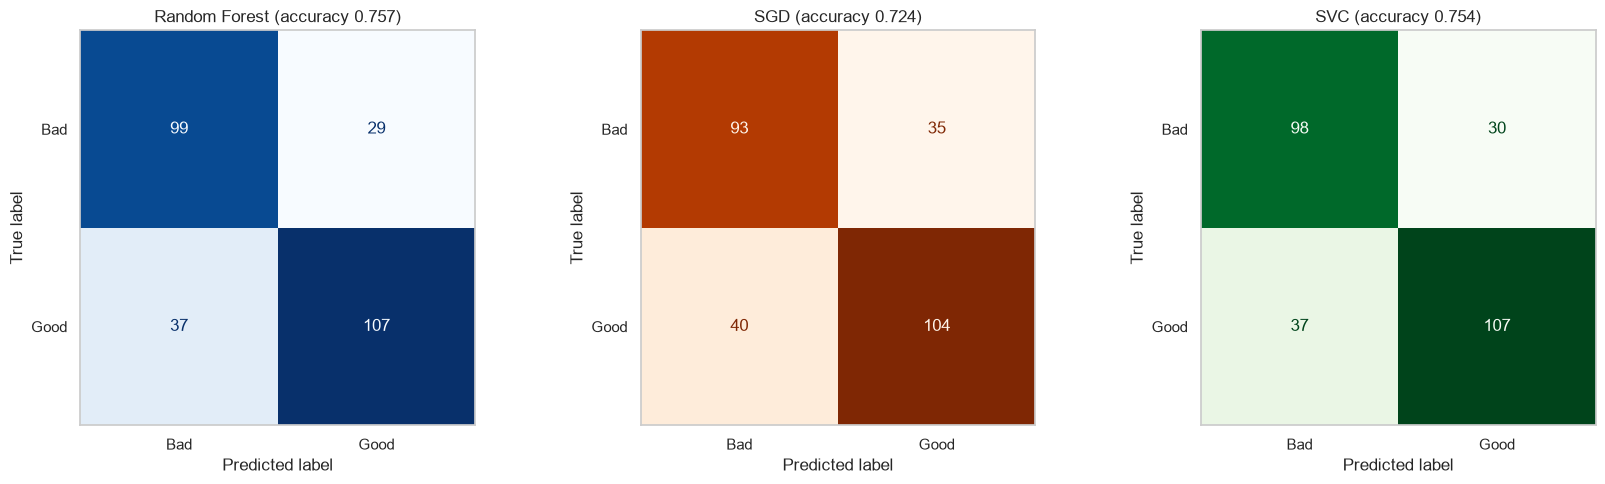

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
models = [("Random Forest", rf_pred, "Blues"), ("SGD", sgd_pred, "Oranges"), ("SVC", svc_pred, "Greens")]

for ax, (name, pred, cmap) in zip(axes, models):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["Bad", "Good"], cmap=cmap, ax=ax, colorbar=False
    )
    ax.set_title(f"{name} (accuracy {accuracy_score(y_test, pred):.3f})")
    ax.grid(False)

plt.tight_layout()
plt.show()

In [29]:
for name, pred, _ in models:
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"{name}: correct bad={tn}, bad called good={fp}, good called bad={fn}, correct good={tp}")

Random Forest: correct bad=99, bad called good=29, good called bad=37, correct good=107
SGD: correct bad=93, bad called good=35, good called bad=40, correct good=104
SVC: correct bad=98, bad called good=30, good called bad=37, correct good=107


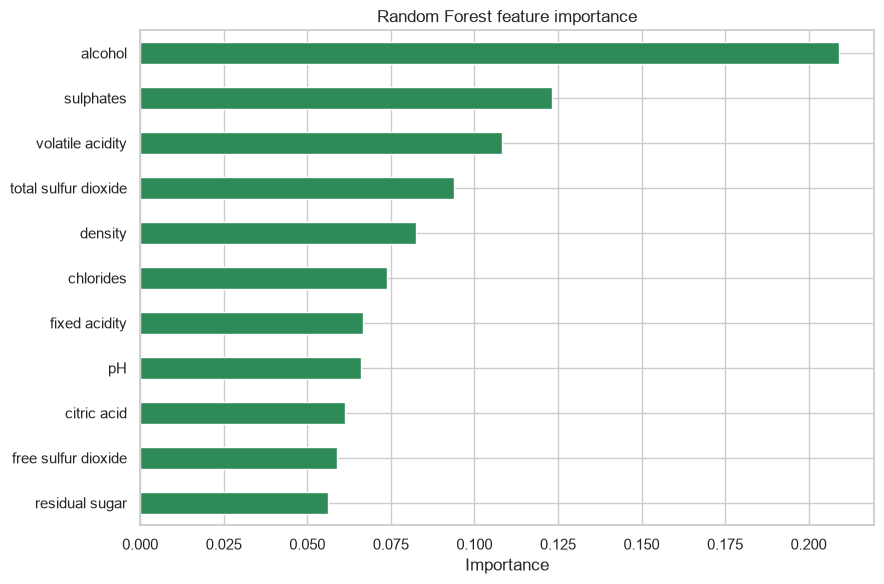

In [30]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(9, 6))
importances.plot.barh(color="seagreen")
plt.title("Random Forest feature importance")
plt.xlabel("Importance")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [31]:
print(importances.sort_values(ascending=False).round(3))
print()
print("Top 3 share of total importance:", round(importances.nlargest(3).sum() * 100, 1), "%")

alcohol                 0.209
sulphates               0.123
volatile acidity        0.108
total sulfur dioxide    0.094
density                 0.082
chlorides               0.074
fixed acidity           0.067
pH                      0.066
citric acid             0.061
free sulfur dioxide     0.059
residual sugar          0.056
dtype: float64

Top 3 share of total importance: 44.1 %


In [32]:
import time
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import precision_score, recall_score, f1_score

In [33]:
setups = [
    ("Random Forest", rf, X_train, X_test),
    ("SGD", sgd, X_train_scaled, X_test_scaled),
    ("SVC", svc, X_train_scaled, X_test_scaled),
]

rows = []
for name, model, Xtr, Xte in setups:
    pred = model.predict(Xte)
    rows.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, model.predict(Xtr)),
        "Test Accuracy": accuracy_score(y_test, pred),
        "Precision (Good)": precision_score(y_test, pred),
        "Recall (Good)": recall_score(y_test, pred),
        "F1 (Good)": f1_score(y_test, pred),
        "Macro F1": f1_score(y_test, pred, average="macro"),
    })

comparison = pd.DataFrame(rows).set_index("Model").round(3)
comparison

,Train Accuracy,Test Accuracy,Precision (Good),Recall (Good),F1 (Good),Macro F1
Model,,,,,,
Random Forest,1.000,0.757,0.787,0.743,0.764,0.757
SGD,0.740,0.724,0.748,0.722,0.735,0.724
SVC,0.791,0.754,0.781,0.743,0.762,0.753


In [34]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

pipes = {
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "SGD": Pipeline([("scale", StandardScaler()), ("clf", SGDClassifier(max_iter=1000, random_state=42))]),
    "SVC": Pipeline([("scale", StandardScaler()), ("clf", SVC(kernel="rbf", random_state=42))]),
}

cv_rows = []
for name, pipe in pipes.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")
    cv_rows.append({"Model": name, "CV Mean Accuracy": scores.mean(), "CV Std": scores.std()})

cv_table = pd.DataFrame(cv_rows).set_index("Model").round(3)
cv_table

,CV Mean Accuracy,CV Std
Model,,
Random Forest,0.744,0.046
SGD,0.685,0.042
SVC,0.746,0.037


In [35]:
timing = []
for name, model, Xtr, Xte in setups:
    t0 = time.perf_counter()
    model.fit(Xtr, y_train)
    fit_time = time.perf_counter() - t0
    t0 = time.perf_counter()
    model.predict(Xte)
    pred_time = time.perf_counter() - t0
    timing.append({"Model": name, "Fit time (s)": fit_time, "Predict time (s)": pred_time})

pd.DataFrame(timing).set_index("Model").round(4)

,Fit time (s),Predict time (s)
Model,,
Random Forest,0.9610,0.0341
SGD,0.0101,0.0008
SVC,0.0537,0.0207


In [36]:
final = comparison[["Test Accuracy", "Precision (Good)", "Recall (Good)", "F1 (Good)"]].join(cv_table)
final["Gap (Train - Test)"] = (comparison["Train Accuracy"] - comparison["Test Accuracy"]).round(3)
final

,Test Accuracy,Precision (Good),Recall (Good),F1 (Good),CV Mean Accuracy,CV Std,Gap (Train - Test)
Model,,,,,,,
Random Forest,0.757,0.787,0.743,0.764,0.744,0.046,0.243
SGD,0.724,0.748,0.722,0.735,0.685,0.042,0.016
SVC,0.754,0.781,0.743,0.762,0.746,0.037,0.037


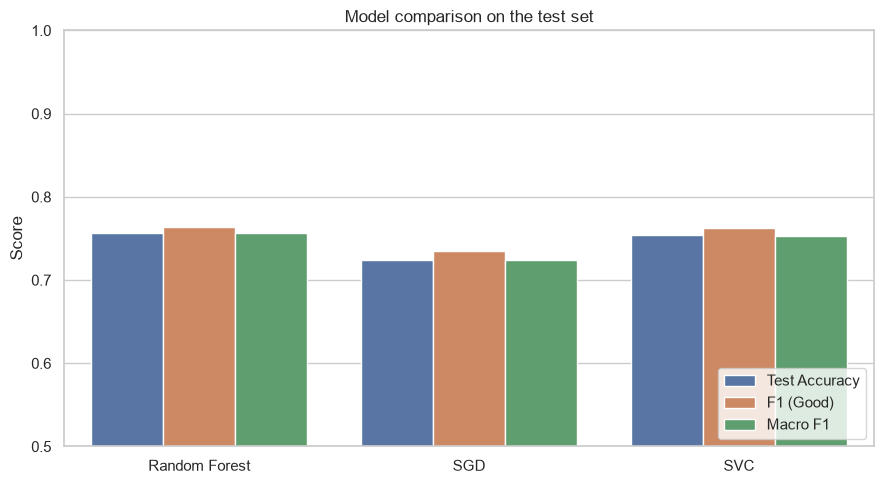

In [37]:
plot_df = comparison[["Test Accuracy", "F1 (Good)", "Macro F1"]].reset_index().melt(
    id_vars="Model", var_name="Metric", value_name="Score")

plt.figure(figsize=(9, 5))
sns.barplot(data=plot_df, x="Model", y="Score", hue="Metric")
plt.ylim(0.5, 1.0)
plt.title("Model comparison on the test set")
plt.ylabel("Score")
plt.xlabel("")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [38]:
best = comparison["Test Accuracy"].idxmax()
print("Best test accuracy:", best, comparison.loc[best, "Test Accuracy"])
print("Best CV accuracy:", cv_table["CV Mean Accuracy"].idxmax(), cv_table["CV Mean Accuracy"].max())

Best test accuracy: Random Forest 0.757
Best CV accuracy: SVC 0.746


In [39]:
import joblib
joblib.dump(rf, "wine_quality_rf_model.joblib")

['wine_quality_rf_model.joblib']

In [40]:
joblib.dump(svc, "wine_quality_svc_model.joblib")
joblib.dump(scaler, "wine_quality_scaler.joblib")

['wine_quality_scaler.joblib']

## Conclusion: Which Model Is Best for Deployment?

### Model comparison

| Model | Test Accuracy | Precision (Good) | Recall (Good) | F1 (Good) | Macro F1 | CV Accuracy (mean ± std) | Train-Test Gap |
|---|---|---|---|---|---|---|---|
| Random Forest | 0.757 | 0.787 | 0.743 | 0.764 | 0.76 | 0.744 ± 0.046 | 0.243 |
| SGD | 0.724 | 0.748 | 0.722 | 0.735 | 0.72 | 0.685 ± 0.042 | 0.016 |
| SVC | 0.754 | 0.781 | 0.743 | 0.762 | 0.75 | 0.746 ± 0.037 | 0.037 |

Test set: 272 wines. Cross-validation: 5-fold stratified on the training set, with scaling done inside each fold.

### Confusion matrix summary

| Model | Bad correct | Bad called Good | Good called Bad | Good correct | Total correct |
|---|---|---|---|---|---|
| Random Forest | 99 | 29 | 37 | 107 | 206 |
| SGD | 93 | 35 | 40 | 104 | 197 |
| SVC | 98 | 30 | 37 | 107 | 205 |

### Key findings
- **Random Forest and SVC are effectively tied.** Their test accuracies (75.7% vs 75.4%) differ by one wine out of 272, and their cross-validation scores (74.4% vs 74.6%) differ by far less than the fold-to-fold variation (about ±4 points). The data cannot separate them.
- **SGD is clearly the weakest.** It is about 3 points lower on the test set and about 6 points lower in cross-validation. A linear decision boundary is too simple for this data, and SGD also makes the most errors of both kinds.
- **Random Forest overfits.** Its training accuracy is almost 100%, a gap of 0.243 from its test accuracy. SGD (0.016) and SVC (0.037) generalise much more consistently. Random Forest's held-out performance is still as good as SVC's, so the overfitting does not hurt test results here, but it means training accuracy says little about it.
- **SVC is the most stable model**, with the lowest cross-validation variation (±0.037) and a small train-test gap.
- **Errors are balanced across classes.** Precision and recall for Bad and Good are within a few points of each other for all three models, which is expected after binarising the target into a roughly 53/47 split.
- **All models plateau near 75%.** Wine quality is a subjective tasting score, and 11 chemical measurements cannot fully explain it.

### Feature importance (Random Forest)
Alcohol (0.209), sulphates (0.123) and volatile acidity (0.108) are the most important features and together account for 44.1% of total importance. Total sulfur dioxide (0.094) and density (0.082) follow. This agrees with the correlation analysis, where alcohol (+0.48) and volatile acidity (-0.40) had the strongest relationships with quality. Residual sugar (0.056) and free sulfur dioxide (0.059) matter least. Because some features are correlated (for example density with alcohol and fixed acidity), importance can be shared between them, so the ranking is a guide rather than an exact measure.

### Recommendation
**Random Forest is the recommended model for deployment, with SVC as a close alternative.**

Since accuracy cannot separate the two, the decision rests on practical factors:
1. **Equal or better accuracy:** it has the highest test accuracy (75.7%), the best F1 for the Good class (0.764), and cross-validation within 0.2 points of SVC.
2. **Simpler deployment:** it works on raw feature values. SVC and SGD need the fitted scaler saved and applied to every new wine, an extra step where mistakes can happen.
3. **Interpretability:** feature importances show that alcohol, sulphates and volatile acidity drive predictions, which gives winemakers something actionable. An RBF-kernel SVC offers no comparable view.
4. **Robustness to skew and outliers:** chlorides, residual sugar and sulphates are strongly skewed with many outliers, and tree-based models handle this without transformation.

**When to choose SVC instead:** if consistent, lower-variance performance matters more than interpretability, SVC is the better pick. It has the smallest cross-validation spread and a much smaller train-test gap.

**Not recommended:** SGD, because it is the least accurate on both the test set and in cross-validation. Its only advantage is speed, which is not needed for a dataset this small.

### Limitations
- The target was binarised (good = quality >= 6), so the model cannot predict an exact score, and information is lost (a 6 and an 8 are both labelled good).
- The dataset is small (1,359 wines after removing 240 duplicates) and covers only red wine, so results may not transfer to white wine or other regions.
- With a 272-wine test set, differences of one or two wines are not meaningful, which is why cross-validation was added.
- Quality is a subjective rating, which limits the accuracy any model can reach.
- Hyperparameters were left mostly at their defaults. Limiting the tree depth of Random Forest, or tuning with GridSearchCV, could reduce overfitting and improve all three models, and might change the ranking.

In [41]:
%%writefile README.md
# Task 2 · Wine Quality Prediction

**Track:** Data Analytics · **Internship:** OIBSIP

## Objective
Train and compare multiple classification models to predict the quality of red wine from its physicochemical properties (acidity, density, alcohol content and others).

## Tech Stack
Python, pandas, numpy, scikit-learn (Random Forest, SGD, SVC), seaborn, matplotlib, Jupyter Notebook

## Dataset
[Wine Quality dataset (UCI Machine Learning Repository)](https://archive.ics.uci.edu/dataset/186/wine+quality), red wine file `winequality-red.csv`.

- 1,599 wines, 11 chemical features, quality score from 3 to 8
- 240 duplicate rows removed, leaving 1,359 wines

The CSV files are not included in this repository. Download them from UCI and place them in the `data/` folder.

## Project Structure
```
DataAnalytics-Task2-WineQualityPrediction/
├── Task2_Wine_Quality_Prediction.ipynb
├── README.md
├── requirements.txt
├── data/            (place the CSV files here)
└── screenshots/     (charts from the analysis)
```

## How to Run
```bash
pip install -r requirements.txt
jupyter notebook Task2_Wine_Quality_Prediction.ipynb
```
Then run all cells from top to bottom (Kernel → Restart & Run All).

## What the Notebook Covers
- [x] Load the dataset, inspect its structure and check the class distribution of quality scores
- [x] EDA: distribution plots for all chemical features, boxplots and a correlation heatmap
- [x] Class imbalance discussion and its effect on modelling
- [x] Feature engineering: quality binned into good (>= 6) vs bad (<= 5), with justification
- [x] Stratified train/test split (80/20)
- [x] Three classifiers: Random Forest, SGD and SVC
- [x] Evaluation: accuracy, classification report and confusion matrix for each model
- [x] Random Forest feature importance chart
- [x] Side-by-side comparison table, with 5-fold cross-validation
- [x] Conclusion: which model is most suitable for deployment and why

## Class Imbalance and Binning
About 82% of wines have quality 5 or 6, while quality 3, 4 and 8 together make up only 6% (10, 53 and 17 wines). A model that always predicts quality 5 would already reach 42.5% accuracy, so plain accuracy is misleading and the rare classes are too small to learn from or evaluate.

Quality was therefore binned into a binary target: **good (quality >= 6)** and **bad (quality <= 5)**. This gives a nearly balanced split (52.9% good, 47.1% bad). Splitting at 7 instead would leave only 13.5% good wines. The trade-off is that the model can no longer predict an exact score.

## Results

| Model | Test Accuracy | F1 (Good) | CV Accuracy (mean ± std) | Train-Test Gap |
|---|---|---|---|---|
| Random Forest | 0.757 | 0.764 | 0.744 ± 0.046 | 0.243 |
| SGD | 0.724 | 0.735 | 0.685 ± 0.042 | 0.016 |
| SVC | 0.754 | 0.762 | 0.746 ± 0.037 | 0.037 |

Test set: 272 wines. Cross-validation: 5-fold stratified, with scaling inside each fold.

### Key Findings
- **Random Forest and SVC are effectively tied.** Their test accuracies differ by one wine out of 272, and their cross-validation scores differ by far less than the fold-to-fold variation.
- **SGD is the weakest model**, about 3 points lower on the test set and about 6 points lower in cross-validation.
- **Random Forest overfits** (training accuracy near 100%), but its held-out performance is still as good as SVC's.
- **Alcohol (0.209), sulphates (0.123) and volatile acidity (0.108)** are the most important features and together account for 44.1% of total importance, which agrees with the correlation analysis.

## Recommendation
**Random Forest is recommended for deployment, with SVC as a close alternative.** Because accuracy cannot separate the two, the choice rests on practical factors: Random Forest needs no feature scaling at prediction time, its feature importances are interpretable for winemakers, and it handles skewed features and outliers without transformation. SVC is the better pick if consistent, lower-variance performance matters more than interpretability. SGD is not recommended because it is the least accurate.

## Limitations
- The target was binarised, so the model cannot predict an exact quality score.
- The dataset is small (1,359 wines) and covers only red wine, so results may not transfer to white wine.
- With a 272-wine test set, a difference of one or two wines is not meaningful, which is why cross-validation was added.
- Quality is a subjective tasting rating, which limits the accuracy any model can reach.
- Hyperparameters were mostly left at their defaults. Tuning (for example GridSearchCV, or limiting tree depth in Random Forest) could reduce overfitting and might change the ranking.

## Screenshots

### Class imbalance and binary target
![Class imbalance](screenshots/class_imbalance.png)

### Feature distributions
![Feature distributions](screenshots/feature_distributions.png)

### Correlation heatmap
![Correlation heatmap](screenshots/correlation_heatmap.png)

### Confusion matrices
![Confusion matrices](screenshots/confusion_matrices.png)

### Random Forest feature importance
![Feature importance](screenshots/feature_importance.png)

### Model comparison
![Model comparison](screenshots/model_comparison.png)

Writing README.md


In [42]:
%%writefile requirements.txt
pandas
numpy
scikit-learn
matplotlib
seaborn
jupyter

Writing requirements.txt


In [43]:
import os
print(os.getcwd())
print(os.listdir("."))

C:\Users\N6N0C\OIBSIP\DataAnalytics-Task2-WineQualityPrediction
['.ipynb_checkpoints', 'anaconda_projects', 'data', 'README.md', 'requirements.txt', 'screenshots', 'Task2_Wine_Quality_Prediction.ipynb', 'wine_quality_rf_model.joblib', 'wine_quality_scaler.joblib', 'wine_quality_svc_model.joblib']
